## Setup and data loading

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

In [2]:
# Configuration
FOLDER = "LAB1_QRNG/data/"
BASIS = ['H', 'V', 'D', 'A', 'R', 'L']  # projectors
VERIFIED_CHANNEL = 2
MEASURING_CHANNEL = 3

def load_filenames(folder_path, file_extension=None):
    """Return sorted file paths from folder, optionally filtered by extension."""
    all_files = os.listdir(folder_path)
    files = [
        os.path.join(folder_path, f)
        for f in all_files
        if os.path.isfile(os.path.join(folder_path, f))
    ]
    if file_extension:
        files = [f for f in files if f.endswith(file_extension)]
    return sorted(files)

def load_tags(filepath):
    """
    Parse time-tag text file.
    Returns:
    - channel_data: dict {channel_number: np.array(times_in_seconds)}
    - unit_sec: float unit time in seconds
    """
    unit_time_tag_ps = None
    channel_data = defaultdict(list)

    with open(filepath, "r") as f:
        lines = f.readlines()

    # 1) unit time tag
    for line in lines:
        s = line.strip()
        if s.startswith("# Unit Time Tag:"):
            val = s.replace("# Unit Time Tag:", "").strip()
            if val.endswith("ps"):
                val = val[:-2]
            unit_time_tag_ps = float(val)
            break

    if unit_time_tag_ps is None:
        raise ValueError("Unit Time Tag not found.")

    unit_sec = unit_time_tag_ps * 1e-12

    # 2) table lines: "<tag>;<channel>"
    for line in lines:
        s = line.strip()
        if ";" not in s:
            continue
        left, right = s.split(";", 1)
        tag_str = left.strip()
        ch_str = right.strip()
        if not tag_str.isdigit() or not ch_str.isdigit():
            continue
        tag = int(tag_str)
        channel = int(ch_str)
        t = tag * unit_sec
        channel_data[channel].append(t)

    # Convert to numpy arrays sorted
    channel_data = {ch: np.array(sorted(ts)) for ch, ts in channel_data.items()}
    return channel_data, unit_sec


## Coincidence finding, delay removal and windowing

In [3]:
def nearest_differences(tags, mes_channel, ver_channel):
    """
    Compute signed time differences between each measuring tag and the nearest verifying tag.
    Linear-time two-pointer sweep on sorted arrays.
    """
    mes = np.asarray(tags[mes_channel])
    ver = np.asarray(tags[ver_channel])
    m, n = len(mes), len(ver)
    out = np.empty(m, dtype=float)
    j = 0
    for i in range(m):
        # advance j toward the nearest neighbor
        while j + 1 < n and abs(ver[j + 1] - mes[i]) <= abs(ver[j] - mes[i]):
            j += 1
        out[i] = mes[i] - ver[j]
    return out

def estimate_delay(diffs, bins=2000):
    """
    Estimate the channel delay as the mode (peak center) of the bell-shaped histogram.
    Returns:
    - centered_diffs: diffs shifted by the delay (peak ~ 0)
    - delay_est: estimated delay
    """
    hist, edges = np.histogram(diffs, bins=bins)
    k = np.argmax(hist)
    delay_est = 0#0.5 * (edges[k] + edges[k+1])
    return diffs - delay_est, delay_est

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def choose_window(diffs_centered, sigma_mult=2.0):
    """
    Filter centered differences by removing border noise and keeping only values
    within sigma_mult * variance window of the Gaussian fit.
    Also plots each step of the process.
    """
    diffs_centered = np.array(diffs_centered)

    cleaned = diffs_centered

    # Step 3: Fit Gaussian
    mu, std = norm.fit(cleaned)
    var = std**2
    x = np.linspace(cleaned.min(), cleaned.max(), 200)
    pdf = norm.pdf(x, mu, std)

    return sigma_mult * var


def filter_window(diffs_centered, window_size):
    """Keep coincidences within |Δt| ≤ window_size."""
    mask = np.abs(diffs_centered) <= window_size
    return diffs_centered[mask], mask


## Prob. extraction and normalization

In [26]:
def analyze_file(filepath, mes_channel, ver_channel, mult=5, verbose=True, plot=False):
    """
    Full pipeline per file:
    - load tags, nearest differences
    - delay removal
    - window selection
    - filter coincidences
    Returns:
    - p_raw: raw coincidence fraction (measuring count / verifying count)
    - p_filtered: filtered coincidence fraction (kept diffs / kept verifying intervals proxy)
    - details dict with intermediate values
    """
    tags, unit = load_tags(filepath)
    diffs = nearest_differences(tags, mes_channel, ver_channel)
    diffs_c, delay = estimate_delay(diffs)

    # Window from centered diffs
    w = choose_window(diffs_c, mult)
    diffs_kept, mask = filter_window(diffs_c, w)

    # Raw and filtered percentages (consistent proxies)
    raw_perc = len(tags[mes_channel]) / max(1, len(tags[ver_channel]))
    # Verified timing intervals as proxy for accidental rate
    ver_intervals = np.diff(tags[ver_channel])
    filtered_perc = len(diffs_kept) / max(1, np.count_nonzero(ver_intervals))

    if verbose:
        print(f"File: {os.path.basename(filepath)}")
        print(f"Unit time: {unit:g} s")
        print(f"Tags: mes={len(tags[mes_channel])}, ver={len(tags[ver_channel])}")
        print(f"Estimated delay: {delay:.3e} s, window: ±{w:.3e} s")
        print(f"Raw %: {raw_perc*100:.3f}%, Filtered %: {filtered_perc*100:.3f}%")

    if plot:
        plt.figure(figsize=(6,4))
        plt.hist(diffs, bins=500, alpha=0.6, label="raw diffs")
        plt.axvline(delay, color='r', ls='--', label=f"delay={delay:.3e}s")
        plt.legend(); plt.title("Nearest differences and delay"); plt.tight_layout(); plt.show()

        plt.figure(figsize=(6,4))
        plt.hist(diffs_c, bins=500, alpha=0.6, label="centered diffs")
        plt.axvline(+w, color='k', ls='--'); plt.axvline(-w, color='k', ls='--')
        plt.legend(); plt.title("Centered diffs with window"); plt.tight_layout(); plt.show()

    details = {
        "unit": unit,
        "delay": delay,
        "window": w,
        "raw_diffs": diffs,
        "centered_diffs": diffs_c,
        "kept_mask": mask,
    }
    return raw_perc, filtered_perc, details

def collect_state_probs(paths, state_name, basis, mes_channel, ver_channel, mult=5, verbose=False, plot = False):
    """
    For a given state, gather probabilities per projector file and normalize per basis pair.
    Returns: dict like { 'H': {'r_prob','f_prob','n_prob'}, ... }
    """
    files = [p for p in paths if state_name in os.path.basename(p)]
    state = {}
    for b in basis:
        # one file per projector
        f = next((fp for fp in files if f"{b}.txt" in os.path.basename(fp)), None)
        if f is None:
            raise FileNotFoundError(f"Missing file for {state_name}_{b}.txt")
        raw, filt, _ = analyze_file(f, mes_channel, ver_channel, mult, verbose=verbose)
        state[b] = {"r_prob": raw, "f_prob": filt, "n_prob": np.nan}

    # normalize per pairs: (H,V), (D,A), (R,L)
    def norm_pair(a_key, b_key):
        a = state[a_key]["f_prob"]
        b = state[b_key]["f_prob"]
        s = a + b
        if s <= 0:
            state[a_key]["n_prob"] = np.nan
            state[b_key]["n_prob"] = np.nan
        else:
            state[a_key]["n_prob"] = a / s
            state[b_key]["n_prob"] = b / s

    norm_pair('H', 'V'); norm_pair('D', 'A'); norm_pair('R', 'L')

    # sanity checks
    def check_pair(a_key, b_key, tol=1e-6):
        a = state[a_key]["n_prob"]; b = state[b_key]["n_prob"]
        if np.isfinite(a) and np.isfinite(b):
            s = a + b
            if abs(s - 1.0) > tol:
                print(f"Warning: {state_name} {a_key}/{b_key} not normalized: {s:.6f}")

    check_pair('H', 'V'); check_pair('D', 'A'); check_pair('R', 'L')
    return state

def print_prob_table(state):
    headers = ["Key", "raw", "filtered", "normalized"]
    rows = []
    for k in ['H','V','D','A','R','L']:
        v = state[k]
        rows.append([k, v['r_prob'], v['f_prob'], v['n_prob']])

    col_widths = [max(len(headers[i]), max(len(str(r[i])) for r in rows)) for i in range(4)]
    line = " ".join(headers[i].ljust(col_widths[i]) for i in range(4))
    print(line); print("-" * (sum(col_widths) + 3))
    for r in rows:
        print(f"{r[0].ljust(col_widths[0])} "
              f"{r[1]:<{col_widths[1]}.6f} "
              f"{r[2]:<{col_widths[2]}.6f} "
              f"{r[3]:<{col_widths[3]}.6f}")


## state reconstruction and physicality

In [5]:
# Pauli matrices
I = np.array([[1, 0],[0, 1]], dtype=complex)
X = np.array([[0, 1],[1, 0]], dtype=complex)
Y = np.array([[0, -1j],[1j, 0]], dtype=complex)
Z = np.array([[1, 0],[0, -1]], dtype=complex)

def bloch_components(state):
    """Compute Bloch vector r from normalized probabilities."""
    rx = state['D']['n_prob'] - state['A']['n_prob']
    ry = state['R']['n_prob'] - state['L']['n_prob']
    rz = state['H']['n_prob'] - state['V']['n_prob']
    r = np.array([rx, ry, rz], dtype=float)
    return r, np.linalg.norm(r)

def project_bloch(r):
    """Project r into the Bloch ball if |r|>1."""
    n = np.linalg.norm(r)
    if n > 1:
        return r / n
    return r

def density_matrix_from_bloch(r):
    """ρ = 1/2 (I + r·σ)"""
    return 0.5 * (I + r[0]*X + r[1]*Y + r[2]*Z)

def print_matrix(M, name=""):
    def fmt(z):
        r, im = z.real, z.imag
        if abs(im) < 1e-12: return f"{r:8.4f}"
        sign = "+" if im >= 0 else "-"
        return f"{r:6.4f} {sign} {abs(im):.4f}i"
    print(f"\n- {name} -")
    for row in M:
        print("| " + " ".join(fmt(z) for z in row) + " |")



## Security metrics

entropy calculation

In [6]:
def h_min(probabilities):
    return -np.log2(np.max(probabilities))

def h_shannon(probabilities):
    """Shannon entropy for binary {p, 1-p}."""
    entropy = 0
    for p in probabilities:
        if p > 0:
            entropy -= p * np.log2(p)
    return entropy

def h_max(probabilities):
    """Maxwell entropy for binary {p, 1-p}."""
    entropy = 0
    for p in probabilities:
        if p > 0:
            entropy += np.sqrt(p)
    return 2 * np.log2(entropy)
    

In [7]:
def trusted_min_entropy(state, basis = ('H', 'V')):
    """Trusted protocol: min-entropy from one chosen basis pair."""
    pa = state[basis[0]]['n_prob']
    pb = state[basis[1]]['n_prob']
    if not np.isfinite(pa):
        return np.nan
    return h_min((pa,pb))

def sdi_eup_metrics(state, basis=(('H','V'))):
    """
    SDI–EUP: return min-entropis bounded bi the EUP relation
    eup Hmin(A|E) + Hmax(B|E) >= 1 for MUB pairs A,B
    since c = 0.5 for qubit MUBs. -> log2(c) = 1
    So Hmin(A|E) >= 1 - Hmax(B|E)
    """
    pa = state[basis[0]]['n_prob']
    pb = state[basis[1]]['n_prob']
    return 1 - h_max((pa,pb))

def sdi_tomo_min_entropy(state):
    """SDI–TOMO: use |r| to bound optimal guess probability."""
    r, n = bloch_components(state)
    r_proj = project_bloch(r)
    n_proj = np.linalg.norm(r_proj)
    return -np.log2((1 + n_proj)/2), {"r": r, "norm": n, "r_proj": r_proj, "norm_proj": n_proj}

def sdi_povm_min_entropy(rho):
    """
    SDI–POVM (square POVM): F_k = (1/2)|k><k| for k∈{H,V,D,A}.
    Compute p_k ∝ Tr(|k><k| ρ), renormalize over H,V,D,A, return min-entropy.
    """
    def proj(vec):
        v = np.asarray(vec, dtype=complex).reshape(2,1)
        return v @ v.conj().T

    # Computational basis |H>=|0>, |V>=|1>
    H = np.array([1,0]); V = np.array([0,1])
    # Diagonal basis |D>=(|0>+|1>)/√2, |A>=(|0>-|1>)/√2
    D = (H + V)/np.sqrt(2)
    A = (H - V)/np.sqrt(2)

    P = {
        'H': proj(H),
        'V': proj(V),
        'D': proj(D),
        'A': proj(A),
    }
    raw = np.array([np.real(np.trace(P[k] @ rho)) for k in ['H','V','D','A']], dtype=float)
    s = raw.sum()
    if s <= 0:
        return np.nan, {"p": raw, "sum": s}
    p = raw / s
    pmax = np.max(p)
    return -np.log2(pmax), {"p": p}


## running test

In [8]:
def evaluate_state(paths, state_name, mult = 5, verbose=False, plot = False):
    """
    Build probabilities, reconstruct state, and compute all protocol metrics.
    Tests:
    - Single bases: H/V, D/A, R/L (Trusted)
    - MUB pairs: (H/V & D/A), (H/V & R/L) (SDI–EUP)
    - All three bases (SDI–TOMO, SDI–POVM)
    """
    state = collect_state_probs(
        paths, state_name, BASIS, MEASURING_CHANNEL, VERIFIED_CHANNEL,
        mult, verbose=verbose, plot=plot
    )
    print(f"\n== {state_name} ==")
    print_prob_table(state)

    # Trusted (each pair separately)
    trusted_results = {
        "HV": trusted_min_entropy(state, ('H','V')),
        "DA": trusted_min_entropy(state, ('D','A')),
        "RL": trusted_min_entropy(state, ('R','L')),
    }

    # SDI–EUP (two MUB pairs)
    eup_HV_DA = sdi_eup_metrics(state, ('D','A'))
    eup_HV_RL = sdi_eup_metrics(state, ('R','L'))

    # SDI–TOMO
    hmin_tomo, tomo_info = sdi_tomo_min_entropy(state)
    rho = density_matrix_from_bloch(tomo_info["r_proj"])

    # SDI–POVM
    hmin_povm, povm_info = sdi_povm_min_entropy(rho)

    # Print concise summary
    print("\nTrusted min-entropy (per basis):")
    for k, v in trusted_results.items():
        print(f"  {k}: {v:.3f} bits")

    print("\nSDI–EUP:")
    print(f"  HV & DA conservative hmin: {eup_HV_DA:.3f} bits")
    print(f"  HV & RL conservative hmin: {eup_HV_RL:.3f} bits")

    print("\nSDI–TOMO:")
    print(f"  |r| (proj): {tomo_info['norm_proj']:.3f}, hmin: {hmin_tomo:.3f} bits")

    print("\nSDI–POVM:")
    print(f"  min-entropy: {hmin_povm:.3f} bits, probs: {povm_info['p']}")

    return {
        "state_table": state,
        "trusted": trusted_results,
        "eup_HV_DA": eup_HV_DA,
        "eup_HV_RL": eup_HV_RL,
        "tomo": {"hmin": hmin_tomo, **tomo_info},
        "rho": rho,
        "povm": {"hmin": hmin_povm, **povm_info},
    }


## main

In [29]:
# Load paths
paths = load_filenames(FOLDER, file_extension=".txt")
mult = 10  # coincidence window quantile

In [30]:
mixed_metrics = evaluate_state(paths, "mixed_measured", mult = mult, verbose=True, plot= False)

File: mixed_measured_H.txt
Unit time: 8.0955e-11 s
Tags: mes=1388438, ver=3566765
Estimated delay: 0.000e+00 s, window: ±1.411e-09 s
Raw %: 38.927%, Filtered %: 3.959%
File: mixed_measured_V.txt
Unit time: 8.0955e-11 s
Tags: mes=1619263, ver=3470093
Estimated delay: 0.000e+00 s, window: ±1.417e-09 s
Raw %: 46.663%, Filtered %: 4.509%
File: mixed_measured_D.txt
Unit time: 8.0955e-11 s
Tags: mes=1569247, ver=3596391
Estimated delay: 0.000e+00 s, window: ±1.422e-09 s
Raw %: 43.634%, Filtered %: 4.287%
File: mixed_measured_A.txt
Unit time: 8.0955e-11 s
Tags: mes=1388989, ver=3404722
Estimated delay: 0.000e+00 s, window: ±1.433e-09 s
Raw %: 40.796%, Filtered %: 4.154%
File: mixed_measured_R.txt
Unit time: 8.0955e-11 s
Tags: mes=1424323, ver=3490222
Estimated delay: 0.000e+00 s, window: ±1.442e-09 s
Raw %: 40.809%, Filtered %: 4.149%
File: mixed_measured_L.txt
Unit time: 8.0955e-11 s
Tags: mes=1427751, ver=3479546
Estimated delay: 0.000e+00 s, window: ±1.432e-09 s
Raw %: 41.033%, Filtered %:

In [20]:
print_matrix(mixed_metrics["rho"], name="Density Matrix ρ (mixed state)")


- Density Matrix ρ (mixed state) -
|   0.4675 0.0077 + 0.0098i |
| 0.0077 - 0.0098i   0.5325 |


In [11]:
diagonal_metrics = evaluate_state(paths, "diagonal_measured", mult = mult, verbose=False, plot= False)


== diagonal_measured ==
Key raw                  filtered              normalized           
--------------------------------------------------------------------
H   0.179514             0.015597              0.540390             
V   0.155349             0.013265              0.459610             
D   0.306443             0.028748              0.996590             
A   0.011262             0.000098              0.003410             
R   0.153237             0.013887              0.473358             
L   0.171782             0.015450              0.526642             

Trusted min-entropy (per basis):
  HV: 0.888 bits
  DA: 0.005 bits
  RL: 0.925 bits

SDI–EUP:
  HV & DA conservative hmin: 0.841 bits
  HV & RL conservative hmin: 0.001 bits

SDI–TOMO:
  |r| (proj): 0.998, hmin: 0.002 bits

SDI–POVM:
  min-entropy: 1.005 bits, probs: [0.27019514 0.22980486 0.4982949  0.0017051 ]


In [22]:
print_matrix(diagonal_metrics["rho"], name="Density Matrix ρ (diagonal state)")


- Density Matrix ρ (diagonal state) -
|   0.5404 0.4966 + 0.0266i |
| 0.4966 - 0.0266i   0.4596 |


In [12]:
right_metrics = evaluate_state(paths, "right_measured", mult = mult, verbose=False, plot= False)


== right_measured ==
Key raw                  filtered               normalized          
--------------------------------------------------------------------
H   0.125459             0.011043               0.434457            
V   0.157956             0.014376               0.565543            
D   0.134082             0.011968               0.467543            
A   0.151736             0.013629               0.532457            
R   0.278863             0.026014               0.991169            
L   0.012680             0.000232               0.008831            

Trusted min-entropy (per basis):
  HV: 0.822 bits
  DA: 0.909 bits
  RL: 0.013 bits

SDI–EUP:
  HV & DA conservative hmin: 0.002 bits
  HV & RL conservative hmin: 0.753 bits

SDI–TOMO:
  |r| (proj): 0.993, hmin: 0.005 bits

SDI–POVM:
  min-entropy: 1.822 bits, probs: [0.21722827 0.28277173 0.23377149 0.26622851]


In [23]:
print_matrix(right_metrics["rho"], name="Density Matrix ρ (right state)")


- Density Matrix ρ (right state) -
|   0.4345 -0.0325 - 0.4912i |
| -0.0325 + 0.4912i   0.5655 |


In [25]:
unknown_metrics = evaluate_state(paths, "unknown_measured", mult = mult, verbose=False, plot= False)


== unknown_measured ==
Key raw                 filtered              normalized         
-----------------------------------------------------------------
H   0.102763            0.008981              0.332425           
V   0.196827            0.018036              0.667575           
D   0.276003            0.025017              0.911343           
A   0.034612            0.002434              0.088657           
R   0.087622            0.007489              0.295859           
L   0.192912            0.017824              0.704141           

Trusted min-entropy (per basis):
  HV: 0.583 bits
  DA: 0.134 bits
  RL: 0.506 bits

SDI–EUP:
  HV & DA conservative hmin: 0.351 bits
  HV & RL conservative hmin: 0.064 bits

SDI–TOMO:
  |r| (proj): 0.978, hmin: 0.016 bits

SDI–POVM:
  min-entropy: 1.134 bits, probs: [0.16621257 0.33378743 0.45567157 0.04432843]


In [24]:
print_matrix(unknown_metrics["rho"], name="Density Matrix ρ (unkown state)")


- Density Matrix ρ (unkown state) -
|   0.3324 0.4113 + 0.2041i |
| 0.4113 - 0.2041i   0.6676 |


# QRNG construction

In [14]:
def build_qrng(filepath_0, filepath_1, mes_channel, ver_channel, mult=5, verbose=False, plot=False):
    """
    Full pipeline per file:
    - load tags, nearest differences
    - delay removal
    - window selection
    - filter coincidences
    Returns:
    - p_raw: raw coincidence fraction (measuring count / verifying count)
    - p_filtered: filtered coincidence fraction (kept diffs / kept verifying intervals proxy)
    - details dict with intermediate values
    """
    tags_0, unit_0 = load_tags(filepath_0)
    tags_1, unit_1 = load_tags(filepath_1)
    zeros_mask = filter_channel(tags_0, mes_channel, ver_channel)
    ones_mask = filter_channel(tags_1, mes_channel, ver_channel)
    zeros_tag = tags_0[mes_channel][zeros_mask]
    ones_tag = tags_1[mes_channel][ones_mask]
    delay = ones_tag[0] - zeros_tag[0]
    ones_tag_aligned = ones_tag - delay
    return bit_map(ones_tag_aligned, zeros_tag)


def filter_channel(tags, mes_channel, ver_channel, mult = 5):
    diffs = nearest_differences(tags, mes_channel, ver_channel)
    diffs_c, delay = estimate_delay(diffs)
    # Window from centered diffs
    w = choose_window(diffs_c, mult)
    mask = filter_window_mask(diffs_c, w)
    return mask

def filter_window_mask(diffs_centered, window_size):
    """Keep coincidences within |Δt| ≤ window_size."""
    mask = []
    for diff in diffs_centered:
        if abs(diff) <= window_size:
            mask.append(True)
        else:
            mask.append(False)
    return mask

def bit_map(ones_tag, zeros_tag):
    bit_sequence = []
    i, j = 0, 0
    len_ones = len(ones_tag)
    len_zeros = len(zeros_tag)

    while i < len_ones and j < len_zeros:
        if ones_tag[i] < zeros_tag[j]:
            bit_sequence.append(1)
            i += 1
        else:
            bit_sequence.append(0)
            j += 1

    # Append remaining bits
    while i < len_ones:
        bit_sequence.append(1)
        i += 1
    while j < len_zeros:
        bit_sequence.append(0)
        j += 1

    return bit_sequence

In [15]:
path_zeros = "LAB1_QRNG/data/mixed_measured_H.txt"
path_ones = "LAB1_QRNG/data/mixed_measured_V.txt"
bit_sequence = build_qrng(path_zeros, path_ones, MEASURING_CHANNEL, VERIFIED_CHANNEL, mult=7, verbose=True, plot=False)
print(f"Generated QRNG bit sequence of length: {len(bit_sequence)}")

Generated QRNG bit sequence of length: 196669


In [16]:
print("First 100 bits of the QRNG sequence:")
print(bit_sequence[:100])

First 100 bits of the QRNG sequence:
[0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1]


## hashing the bit sequence

### Toeliz hashing

using random seed for simplicity, it would be possible to use a part of the generated key as seed

In [ ]:
def generate_toeplitz_seed(input_bits, output_bits):
    """
    Generate random seed defining a Toeplitz matrix.
    Length = input_bits + output_bits - 1
    """
    return np.random.randint(0, 2, size=input_bits + output_bits - 1, dtype=np.uint8)

In [ ]:
def toeplitz_hash(block_bits, toeplitz_seed, output_bits):
    """
    block_bits: (n,) binary vector
    toeplitz_seed: (n + m - 1,) binary vector
    output_bits: m
    """
    n = len(block_bits)
    m = output_bits

    hash_bits = np.zeros(m, dtype=np.uint8)

    for i in range(m):
        # Toeplitz row i corresponds to seed[i : i+n]
        hash_bits[i] = np.dot(
            toeplitz_seed[i:i+n],
            block_bits
        ) % 2

    return hash_bits


### hashing code

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import hashlib

def plot_theoretical_epsilon(H_min_bit, n_bits=1000, num_blocks=50):
    """
    Plot theoretical epsilon vs block size using LHL.
    H_min_bit: min-entropy per bit
    n_bits: max total block length to consider
    num_blocks: number of block sizes to sample
    """
    # Sample block sizes reasonably
    block_sizes = np.unique(np.linspace(1, n_bits//2, num_blocks, dtype=int))
    # Total min-entropy per block
    H_total = H_min_bit * block_sizes
    # LHL epsilon
    eps = 0.5 * np.sqrt(2**(block_sizes - H_total))
    
    plt.figure(figsize=(8,5))
    plt.plot(block_sizes, eps, 'o-', label="Theoretical ε (LHL)")
    plt.yscale('log')
    plt.xlabel("Block size (bits)")
    plt.ylabel("ε (statistical distance)")
    plt.title(f"Theoretical ε vs block size (H_min per bit = {H_min_bit})")
    plt.grid(True, which="both", ls="--")
    plt.legend()
    plt.show()

def hash_blocks_toeplitz(bit_array, block_size, toeplitz_seed):
    """
    Split binary array into full blocks and hash each block using Toeplitz hashing.
    """
    bit_array = np.array(bit_array, dtype=np.uint8)
    n_bits = len(bit_array)
    n_full_blocks = n_bits // block_size
    hashed_blocks = []

    for i in range(n_full_blocks):
        block = bit_array[i*block_size:(i+1)*block_size]
        hash_bits = toeplitz_hash(block, toeplitz_seed, block_size)
        hashed_blocks.append(hash_bits)

    return hashed_blocks


In [ ]:
H_min_bit = mixed_metrics['tomo']['hmin']
block_size = 10

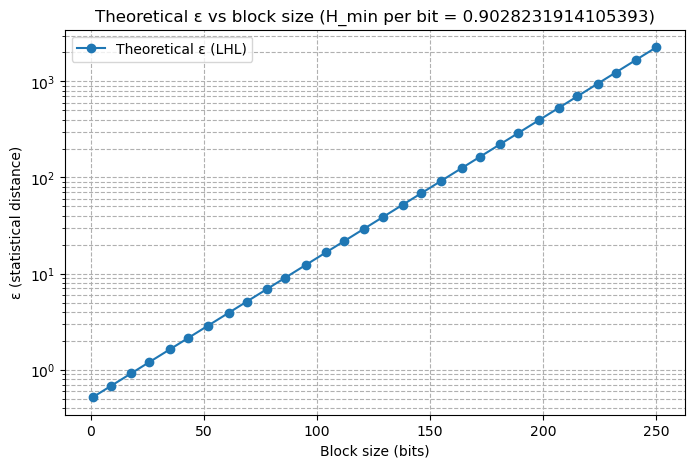

Number of hashed blocks: 19666
First 20 hashed block:
hashed block 0: [1 1 1 1 1 1 1 1 1 1]
hashed block 1: [0 1 1 1 0 0 1 1 0 1]
hashed block 2: [0 1 0 1 0 0 1 0 1 1]
hashed block 3: [0 1 1 1 0 0 0 0 0 1]
hashed block 4: [1 1 1 0 0 1 1 0 0 1]
hashed block 5: [1 0 1 0 0 0 1 1 0 1]
hashed block 6: [1 1 0 0 1 0 1 1 0 0]
hashed block 7: [0 0 1 1 0 0 0 1 1 0]
hashed block 8: [1 0 1 0 0 1 1 0 0 0]
hashed block 9: [1 0 1 1 1 0 0 1 1 1]
hashed block 10: [0 0 1 1 0 0 1 0 1 1]
hashed block 11: [1 1 1 1 1 0 1 0 1 0]
hashed block 12: [0 0 1 1 0 1 1 0 1 1]
hashed block 13: [1 1 0 0 0 0 0 1 1 0]
hashed block 14: [0 0 0 1 0 1 1 0 0 1]
hashed block 15: [1 0 1 0 0 0 1 1 0 1]
hashed block 16: [1 1 1 1 0 1 1 1 1 0]
hashed block 17: [1 0 0 0 1 0 1 1 0 0]
hashed block 18: [0 1 1 0 0 0 0 1 0 1]
hashed block 19: [0 0 1 0 0 1 1 0 0 0]


In [ ]:
plot_theoretical_epsilon(H_min_bit, n_bits=500, num_blocks=30)

# Example: hash blocks of a binary string
np.random.seed(42)
toeplitz_seed = generate_toeplitz_seed(block_size, block_size)
hashed = hash_blocks_toeplitz(bit_sequence, block_size=10)
print(f"Number of hashed blocks: {len(hashed)}")
n_hashed = 20
print(f"First {n_hashed} hashed block:")
for i in range(n_hashed):
    print(f"hashed block {i}: {hashed[i]}")
